# Support Vector Machine (SVM)

In [13]:
%pip install ucimlrepo

import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix

import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import validation_curve


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
chronic_kidney_disease = fetch_ucirepo(id=336)

X = chronic_kidney_disease.data.features.copy()
y_raw = chronic_kidney_disease.data.targets["class"]

# clean text values: strip spaces, turn "?" and "" into NaN
X = X.map(lambda v: v.strip() if isinstance(v, str) else v)   # use .applymap on older pandas
X = X.replace(["?", ""], np.nan)
y_raw = y_raw.str.strip()

# CKD = 1, non-CKD = 0
y = (y_raw == "ckd").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)   # expect (320, 24) and (80, 24)
print(y.value_counts())              # expect 250 CKD, 150 non-CKD

(320, 24) (80, 24)
class
1    250
0    150
Name: count, dtype: int64


In [11]:
ordinal_cols = ["sg", "al", "su"]
cat_cols = ["rbc", "pc", "pcc", "ba", "htn", "dm", "cad", "appet", "pe", "ane"]
num_cols = [c for c in X.columns if c not in cat_cols + ordinal_cols]

for c in num_cols + ordinal_cols:
    X_train[c] = pd.to_numeric(X_train[c], errors="coerce")
    X_test[c] = pd.to_numeric(X_test[c], errors="coerce")

num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("sc", StandardScaler())])
ord_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                     ("sc", StandardScaler())])
cat_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                     ("oh", OneHotEncoder(handle_unknown="ignore"))])

pre = ColumnTransformer([("num", num_pipe, num_cols),
                         ("ord", ord_pipe, ordinal_cols),
                         ("cat", cat_pipe, cat_cols)])

model = Pipeline([
    ("pre", pre),
    ("svm", SVC(kernel="rbf", C=1, gamma="scale",
                class_weight="balanced", probability=True, random_state=42)),
])

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_validate(
    model, X_train, y_train, cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    error_score="raise",
)
for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(f"{m}: {scores['test_'+m].mean():.4f}")

oof = cross_val_predict(model, X_train, y_train, cv=cv)
tn, fp, fn, tp = confusion_matrix(y_train, oof).ravel()
print(f"correct: {tn+tp}/{len(y_train)}  FN: {fn}  FP: {fp}")

accuracy: 0.9906
precision: 1.0000
recall: 0.9850
f1: 0.9924
roc_auc: 1.0000
correct: 317/320  FN: 3  FP: 0


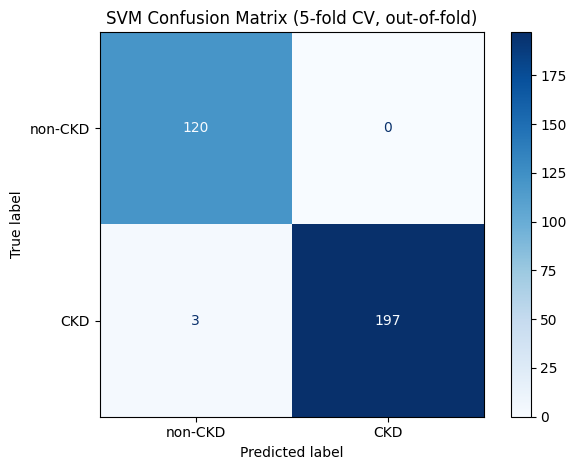

In [15]:
ConfusionMatrixDisplay.from_predictions(
    y_train, oof, display_labels=["non-CKD", "CKD"], cmap="Blues"
)
plt.title("SVM Confusion Matrix (5-fold CV, out-of-fold)")
plt.tight_layout()
plt.show()

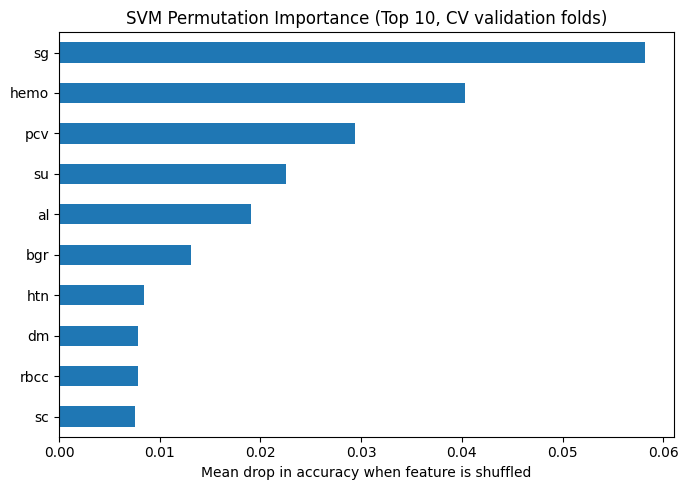

In [16]:
imps = []
for tr_idx, va_idx in cv.split(X_train, y_train):
    m = clone(model).fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    r = permutation_importance(
        m, X_train.iloc[va_idx], y_train.iloc[va_idx],
        scoring="accuracy", n_repeats=10, random_state=42
    )
    imps.append(r.importances_mean)

imp = pd.Series(np.mean(imps, axis=0), index=X_train.columns).sort_values().tail(10)

imp.plot(kind="barh", figsize=(7, 5))
plt.xlabel("Mean drop in accuracy when feature is shuffled")
plt.title("SVM Permutation Importance (Top 10, CV validation folds)")
plt.tight_layout()
plt.show()

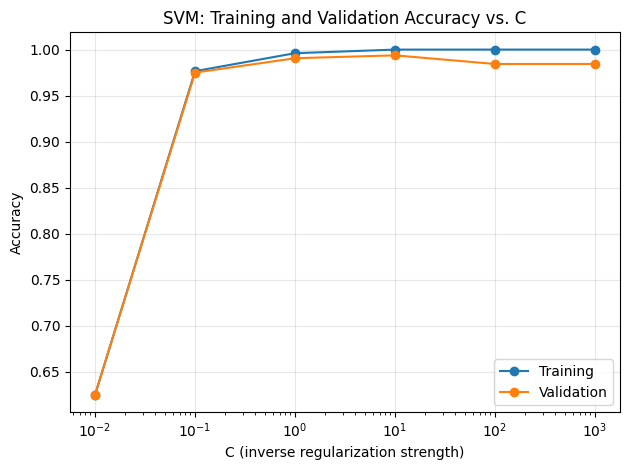

In [17]:
C_range = [0.01, 0.1, 1, 10, 100, 1000]
train_sc, val_sc = validation_curve(
    model, X_train, y_train, param_name="svm__C", param_range=C_range,
    cv=cv, scoring="accuracy"
)

plt.semilogx(C_range, train_sc.mean(axis=1), "o-", label="Training")
plt.semilogx(C_range, val_sc.mean(axis=1), "o-", label="Validation")
plt.xlabel("C (inverse regularization strength)")
plt.ylabel("Accuracy")
plt.title("SVM: Training and Validation Accuracy vs. C")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()